# 09 - Reservoir Quality and Net Pay

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_a_foundations/09_reservoir_quality_and_net_pay.ipynb)

**Part A - Petrophys Curriculum**

This is where the whole Part A pipeline comes together. Having computed clay
volume, porosity, water saturation (lesson 07) and permeability (lesson 08), we
now answer the questions a decision-maker actually asks:

- **How good is the rock?** - flow-zone indicators (RQI/FZI) and flow units.
- **Where is the moveable hydrocarbon?** - bulk-volume water (BVW) and the moveable-
  hydrocarbon index (MHI).
- **How much of the interval is pay?** - the three-stage net-pay flag with porosity,
  saturation and clay cutoffs.
- **How much hydrocarbon is in place?** - volumetrics (HCPV, OOIP, OGIP).

We tie it end-to-end on **30/6-5**, producing a net-pay flag track and a summary
table.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

By the end of this lesson you will be able to:

- Read Rock Quality Index (RQI), normalised porosity ($\phi_z$) and Flow Zone
  Indicator (FZI), and group core plugs into **flow units** with
  `calculate_flow_units`.
- Read bulk-volume water (BVW) and the moveable-hydrocarbon index (MHI), and
  what they say about producibility.
- Apply the **three-stage net-pay** logic (net rock -> net reservoir -> net pay)
  with the standard cutoffs (`STANDARD_CUTOFFS`) or your own (`vcl_cutoff`,
  `phie_cutoff`, `sw_cutoff`), and summarize it per formation or zone.
- Run volumetrics with `calculate_hcpv` and `calculate_ooip` from
  `petrophys.evaluation.summaries`.
- Reproduce an operator's published evaluation with `pp.interpret` settings and
  `zone_summary`.

## Why this matters

A reservoir is not uniformly good. Reservoir-quality workflows sort the rock and
then keep only the part that will actually produce:

- **RQI / FZI** convert porosity and permeability into a *hydraulic* quality metric.
  Rocks with the same FZI have the same pore-throat character and plot on one line -
  a **flow unit**. This is how you zone a reservoir into layers that behave alike.

  $$ RQI = 0.0314\sqrt{k/\phi_e}, \quad \phi_z = \frac{\phi_e}{1-\phi_e}, \quad
     FZI = \frac{RQI}{\phi_z} $$

- **BVW** $= \phi_e \times S_w$ is the fraction of *bulk* rock that is water. In a
  rock at irreducible water, BVW is roughly constant - a hallmark of a clean,
  above-transition-zone reservoir that will produce water-free.

- **MHI** $= S_w / S_{xo}$ compares deep and flushed-zone water. A low MHI ($<0.7$)
  means mud filtrate pushed hydrocarbon out of the near-wellbore rock, so the
  hydrocarbon is **moveable**.

- **Net pay** is the thickness that passes *all* cutoffs. Volumetrics then turn net
  pay, porosity and $S_w$ into barrels or cubic feet in place.

### Prerequisites

Assumes lessons 06 (formation water), 07 (saturation) and 08 (permeability).
`pp.interpret` computes every curve this lesson reads - `RQI`, `FZI`, `BVW`, `MHI`
and the net-pay flags among them - so the lesson runs standalone.

In [2]:
import warnings
import pandas as pd
import petrophys as pp

# The SWC/SOC unit note (lesson 02) repeats on every read of 30/6-5, and formation
# summaries note formations outside the reservoir where PERM_CC is undefined; hide both.
warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")
warnings.filterwarnings("ignore", message=r"PERM_CC is undefined at some net-pay samples")

## 1. Interpret 30/6-5

We interpret the well with the operator's saturation parameters (section 7):
$R_w$ = 0.070 ohm.m at 230 degF, $a = 0.8$, $m = n = 2$, and with the mud filtrate
from its chloride (lesson 06), which the flushed-zone saturation and MHI need. The
reservoir is the Brent Group (2841-2958 m; `BRENT GP.` in the bundled tops).

In [3]:
well = pp.read(pp.sample("30_6-5"), formations=pp.sample("formations_30_6-5"))
operator = dict(rw=0.07, rw_meas_temp="230 degF", a=0.8, m=2, n=2)
result = pp.interpret(well, **operator, rmf_chlorides_mg_l=20366)
brent = "2841 <= DEPTH <= 2958"
result.warnings

['lithology: PEF set aside: in 94% of 331 clean porous samples the apparent matrix density is quartz-like (< 2.67 g/cm3) but the apparent matrix U calcite-like (> 10 b/cm3), the signature of barite-weighted mud; minerals solved without PEF',
 "Bad hole removed 115.33 m of net pay (BAD_HOLE at 12631 of 22176 samples). Check the flag against the caliper and DRHO; bad_hole={'drho': ..., 'cali': ...} sets its thresholds and skip_steps=['bad_hole'] keeps the pay.",
 "The LAS header gives rw_meas_temp=(230.0, 'degF'); not used, rw_meas_temp='230 degF' is set"]

Two warnings. PEF is set aside for the mineral solve because this well was drilled
with barite-weighted mud (lesson 05). The bad-hole flag - caliper and density
correction - removes net pay over the whole well, most of it in the washed-out
shallow section; in the Brent Group it removes 0.3 m of pay, all of it in the Ness
Formation (Exercise 4 repeats the check).

## 2. Rock quality: RQI, $\phi_z$ and FZI

The workflow writes `RQI`, `PHI_Z` and `FZI` along the log, from its porosity and
permeability. But the log permeability is a function of the log porosity, so log
FZI cannot vary at fixed porosity. Flow units are best defined on the well's **real
core plugs** (`PHIC` porosity, `KH_CORE` permeability), where $k$ is measured
independently of $\phi$. `calculate_flow_units(core, n_units=...)` computes RQI,
$\phi_z$ and FZI for every plug and clusters the plugs into hydraulic flow units
(HFUs) by FZI.

In [4]:
from petrophys.evaluation import calculate_flow_units
from petrophys.interpretation.core_analysis.calibration import core_data_from_well

units = calculate_flow_units(core_data_from_well(well), n_units=3)
plugs = units.to_dataframe()
plugs.describe().round(3)

,DEPTH,HFU,RQI,PHI_Z,FZI,PERM_HFU
count,198.000,198.000,198.000,198.000,198.000,198.000
mean,2901.547,2.015,0.881,0.218,3.870,321.421
std,25.506,0.870,1.028,0.090,11.228,437.828
min,2800.481,1.000,0.016,0.022,0.192,0.005
25%,2884.873,1.000,0.069,0.152,0.518,0.819
50%,2904.037,2.000,0.458,0.238,2.141,40.897
75%,2922.020,3.000,1.375,0.289,4.781,682.049
max,2947.852,3.000,4.638,0.383,155.495,1590.930


In [5]:
plugs.nlargest(3, "FZI").round(3)

,DEPTH,HFU,RQI,PHI_Z,FZI,PERM_HFU
156,2924.840,3,3.498,0.022,155.495,0.436
21,2873.785,3,4.597,0.339,13.572,1135.556
22,2874.090,3,4.638,0.364,12.734,1386.162


#### Interpreting FZI

Higher FZI indicates larger, better-connected effective pore throats and
therefore better hydraulic rock quality.

The FZI maximum, though, is not a rock type. It comes from a single suspect plug
at 2924.8 m that pairs a porosity of about 0.02 ($\phi_z$ 0.022) with an RQI of
3.5 um, as high as the best sand's - several hundred mD: a tight plug with a
fracture, or a sample-labelling problem. Its FZI, about 155, is more than ten
times the next highest, and on its own it lifts the mean FZI to 3.9, against a
median of 2.1.
In the flow-unit plot below it sits alone at the far left, inside the best unit.
It is kept in the clustering here, but in a real study it would be flagged and
checked against the core description first.

### Flow units

On a classic FZI plot ($RQI$ vs $\phi_z$, log-log) each flow unit scatters as a
band around its unit-slope FZI line; higher bands are better rock. One plug stands apart
in the upper left: at 2924.8 m it reads a porosity of 0.022 with 273 mD, while the logs
and the plug 0.3 m below (0.203) read about 0.21 there - most likely a misplaced decimal
in its porosity.

,Samples,Mean FZI
HFU,,
1,73,0.43
2,49,1.98
3,76,6.21


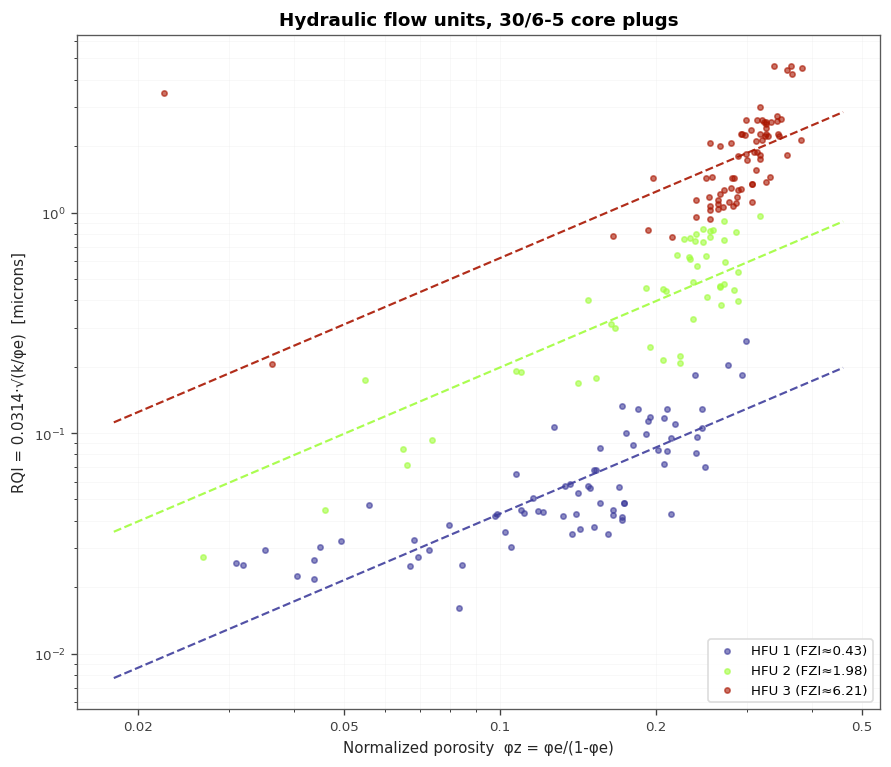

In [6]:
from petrophys.visualization import create_flow_unit_plot

create_flow_unit_plot(units, title="Hydraulic flow units, 30/6-5 core plugs")
units.summary().round(2)

## 3. Bulk-volume water (BVW) and moveable-hydrocarbon index (MHI)

- `BVW` $= \phi_e \times S_w$. A **constant** BVW with depth signals a rock at
  irreducible water (it will flow clean hydrocarbon); rising BVW signals a
  transition zone (it will make water).
- `MHI` $= S_w / S_{xo}$. Rule of thumb: **MHI < 0.7** indicates moveable
  hydrocarbon (the filtrate flushed it away near the borehole); **MHI > 0.7**
  suggests little moveable hydrocarbon.

The porosity track of the plot shades BVW; the MHI track shades MHI below 0.7. In the
clean sand (`VCL` below 0.3), above and below 2900 m:

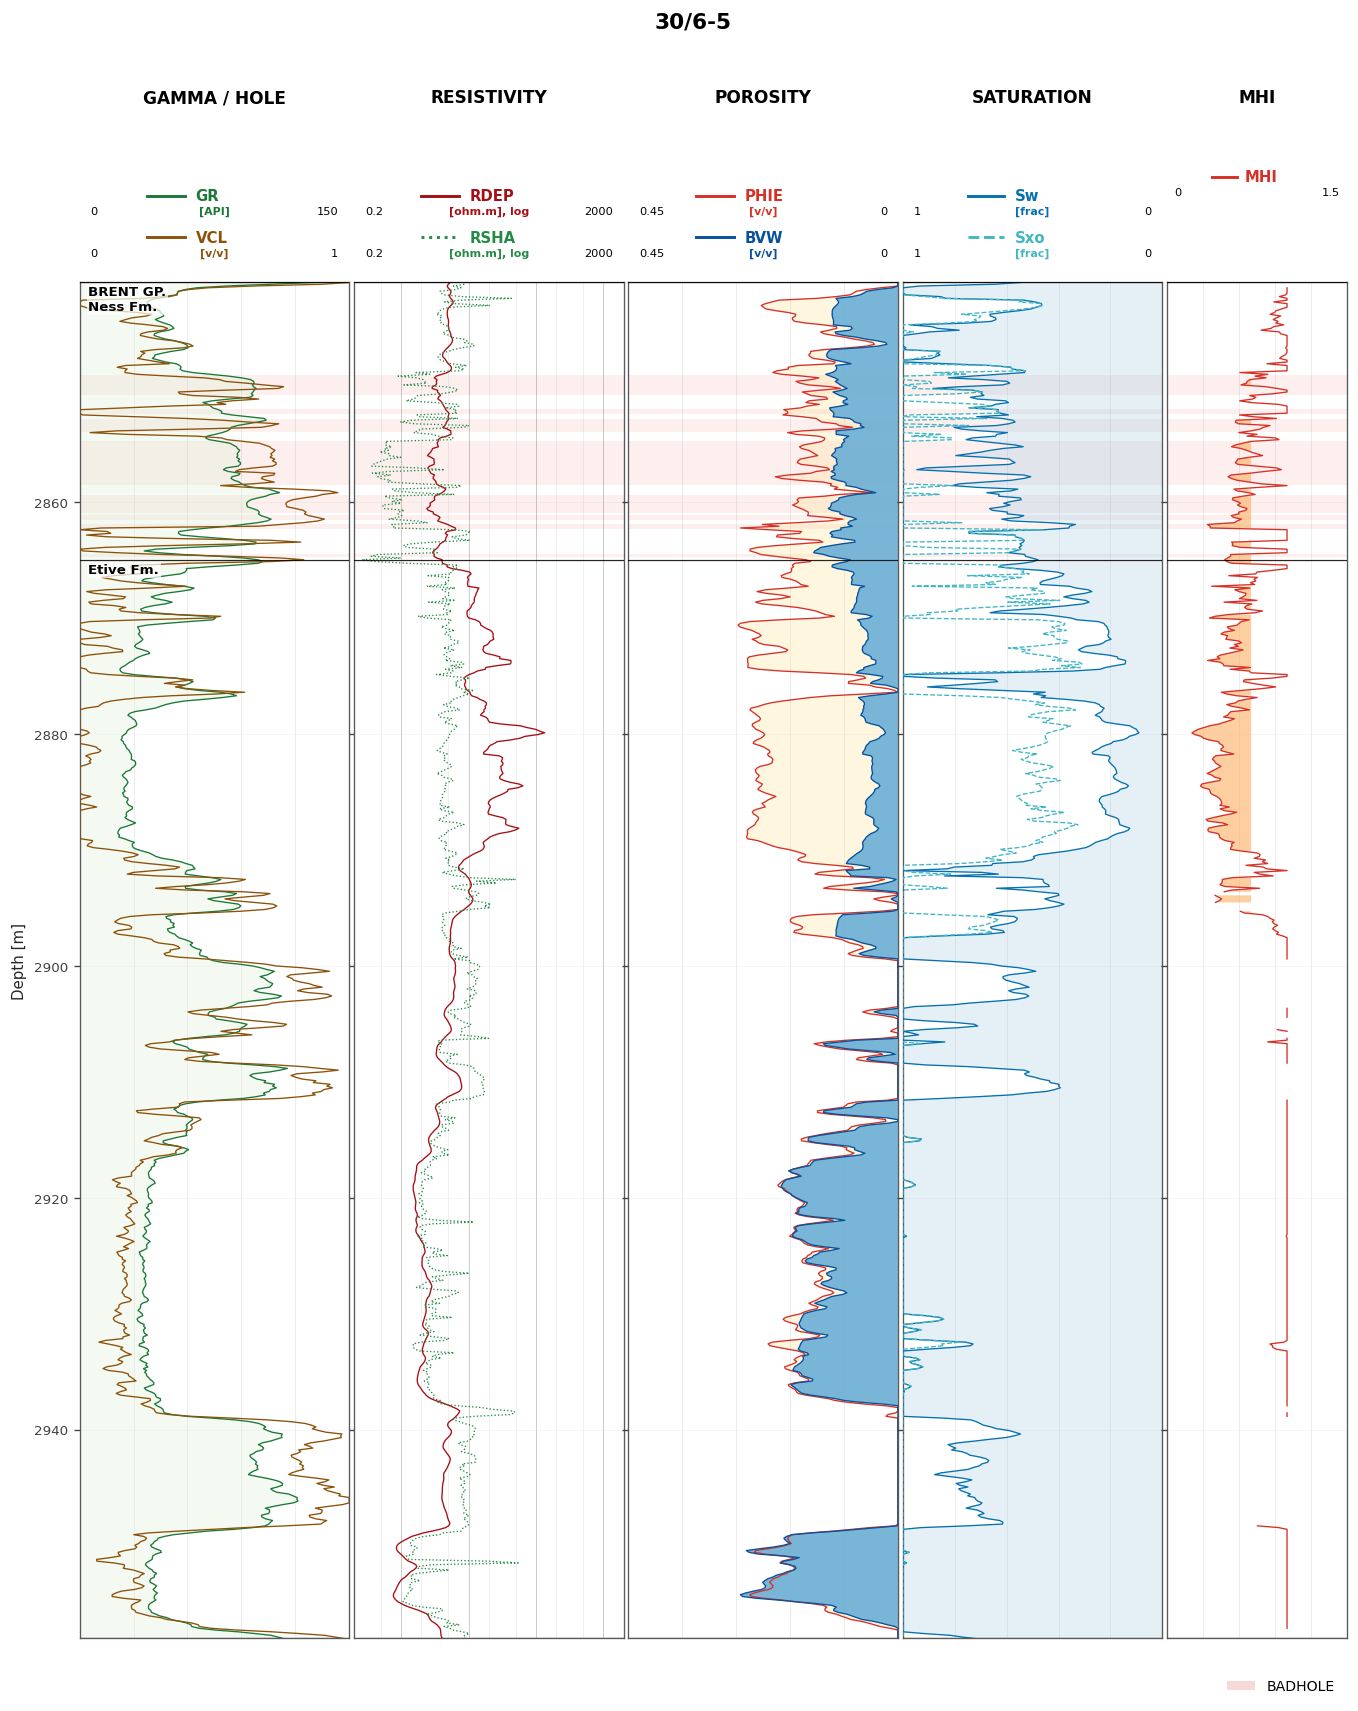

In [7]:
pp.plot(result, top=2841, bottom=2958,
        curves=["GR", "VCL", "RDEP", "RSHA", "PHIE", "BVW", "SW", "SXO", "MHI"])

In [8]:
sand = result.well.to_dataframe().query(brent + " and VCL < 0.3")
above = pd.cut(sand["DEPTH"], [2841, 2900, 2958])
pd.concat([sand.groupby(above)[["BVW", "MHI"]].median(),
           (sand["MHI"] < 0.7).groupby(above).mean().rename("share MHI < 0.7")], axis=1).round(3)

[temporary directory]\ipykernel_31360\704956085.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pd.concat([sand.groupby(above)[["BVW", "MHI"]].median(),
[temporary directory]\ipykernel_31360\704956085.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  (sand["MHI"] < 0.7).groupby(above).mean().rename("share MHI < 0.7")], axis=1).round(3)


,BVW,MHI,share MHI < 0.7
DEPTH,,,
"(2841, 2900]",0.062,0.605,0.584
"(2900, 2958]",0.159,1.000,0.000


#### BVW and moveability interpretation

Above about 2900 m the clean sand's BVW is low (median about 0.06) and the MHI is
below 0.7 at about 60 % of the samples: rock near irreducible water saturation
whose flushed zone has lost hydrocarbon to the filtrate - moveable oil. Below
2900 m BVW is about 2.5 times higher and the MHI is 1: water-bearing sand, nothing
to move. The
change at about 2900 m is the oil-water transition of the Etive Formation.

## 4. Three-stage net pay

Net pay is built in three nested stages, each removing more rock:

1. **Net rock** - remove non-reservoir lithology (clay cutoff: $V_{cl} <$ cutoff).
2. **Net reservoir** - of the net rock, keep only what has enough storage
   (porosity cutoff: $\phi_e >$ cutoff).
3. **Net pay** - of the net reservoir, keep only what is hydrocarbon-bearing
   (saturation cutoff: $S_w <$ cutoff).

`pp.interpret` writes the three flags as `NET_ROCK`, `NET_RES` and `NET_PAY`.
Cutoffs left unset resolve to the **standard cutoffs** (`STANDARD_CUTOFFS`, one set
per lithology family), each sample taking its family's set - the same numbers every
lesson uses, so results are comparable across chapters. It also leaves
non-reservoir samples out of net reservoir and net pay: bad hole, evaporite and
coal, and halite recognised from its logs (lesson 10).

In [9]:
from petrophys.evaluation.net_pay import STANDARD_CUTOFFS

pd.DataFrame(STANDARD_CUTOFFS)

,clastic,carbonate
vcl_cutoff,0.40,0.300
phie_cutoff,0.08,0.045
sw_cutoff,0.60,0.700


`formation_summary` turns the flags into thicknesses per formation, with porosity,
$S_w$, clay volume and permeability averaged over the net-pay samples only:

In [10]:
summary = result.formation_summary().set_index("Formation")
summary.loc[["Ness Fm.", "Etive Fm."], ["Gross (m)", "Net Rock (m)", "Net Reservoir (m)", "Net Pay (m)",
                                        "Pay/Gross", "Avg PHIE", "Avg Sw", "Avg VCL"]].round(3)

,Gross (m),Net Rock (m),Net Reservoir (m),Net Pay (m),Pay/Gross,Avg PHIE,Avg Sw,Avg VCL
Formation,,,,,,,,
Ness Fm.,24.079,11.125,7.620,3.200,0.133,0.206,0.535,0.092
Etive Fm.,92.964,65.379,58.369,23.927,0.257,0.219,0.252,0.067


### The net-pay flag track

The flags track of the plot makes the three-stage filtering visible: each stage is
a subset of the one before it. The fourth flag, Seal, is not a pay stage: it marks
shale, a clay volume of 0.8 or more (`SEALFLAG`).

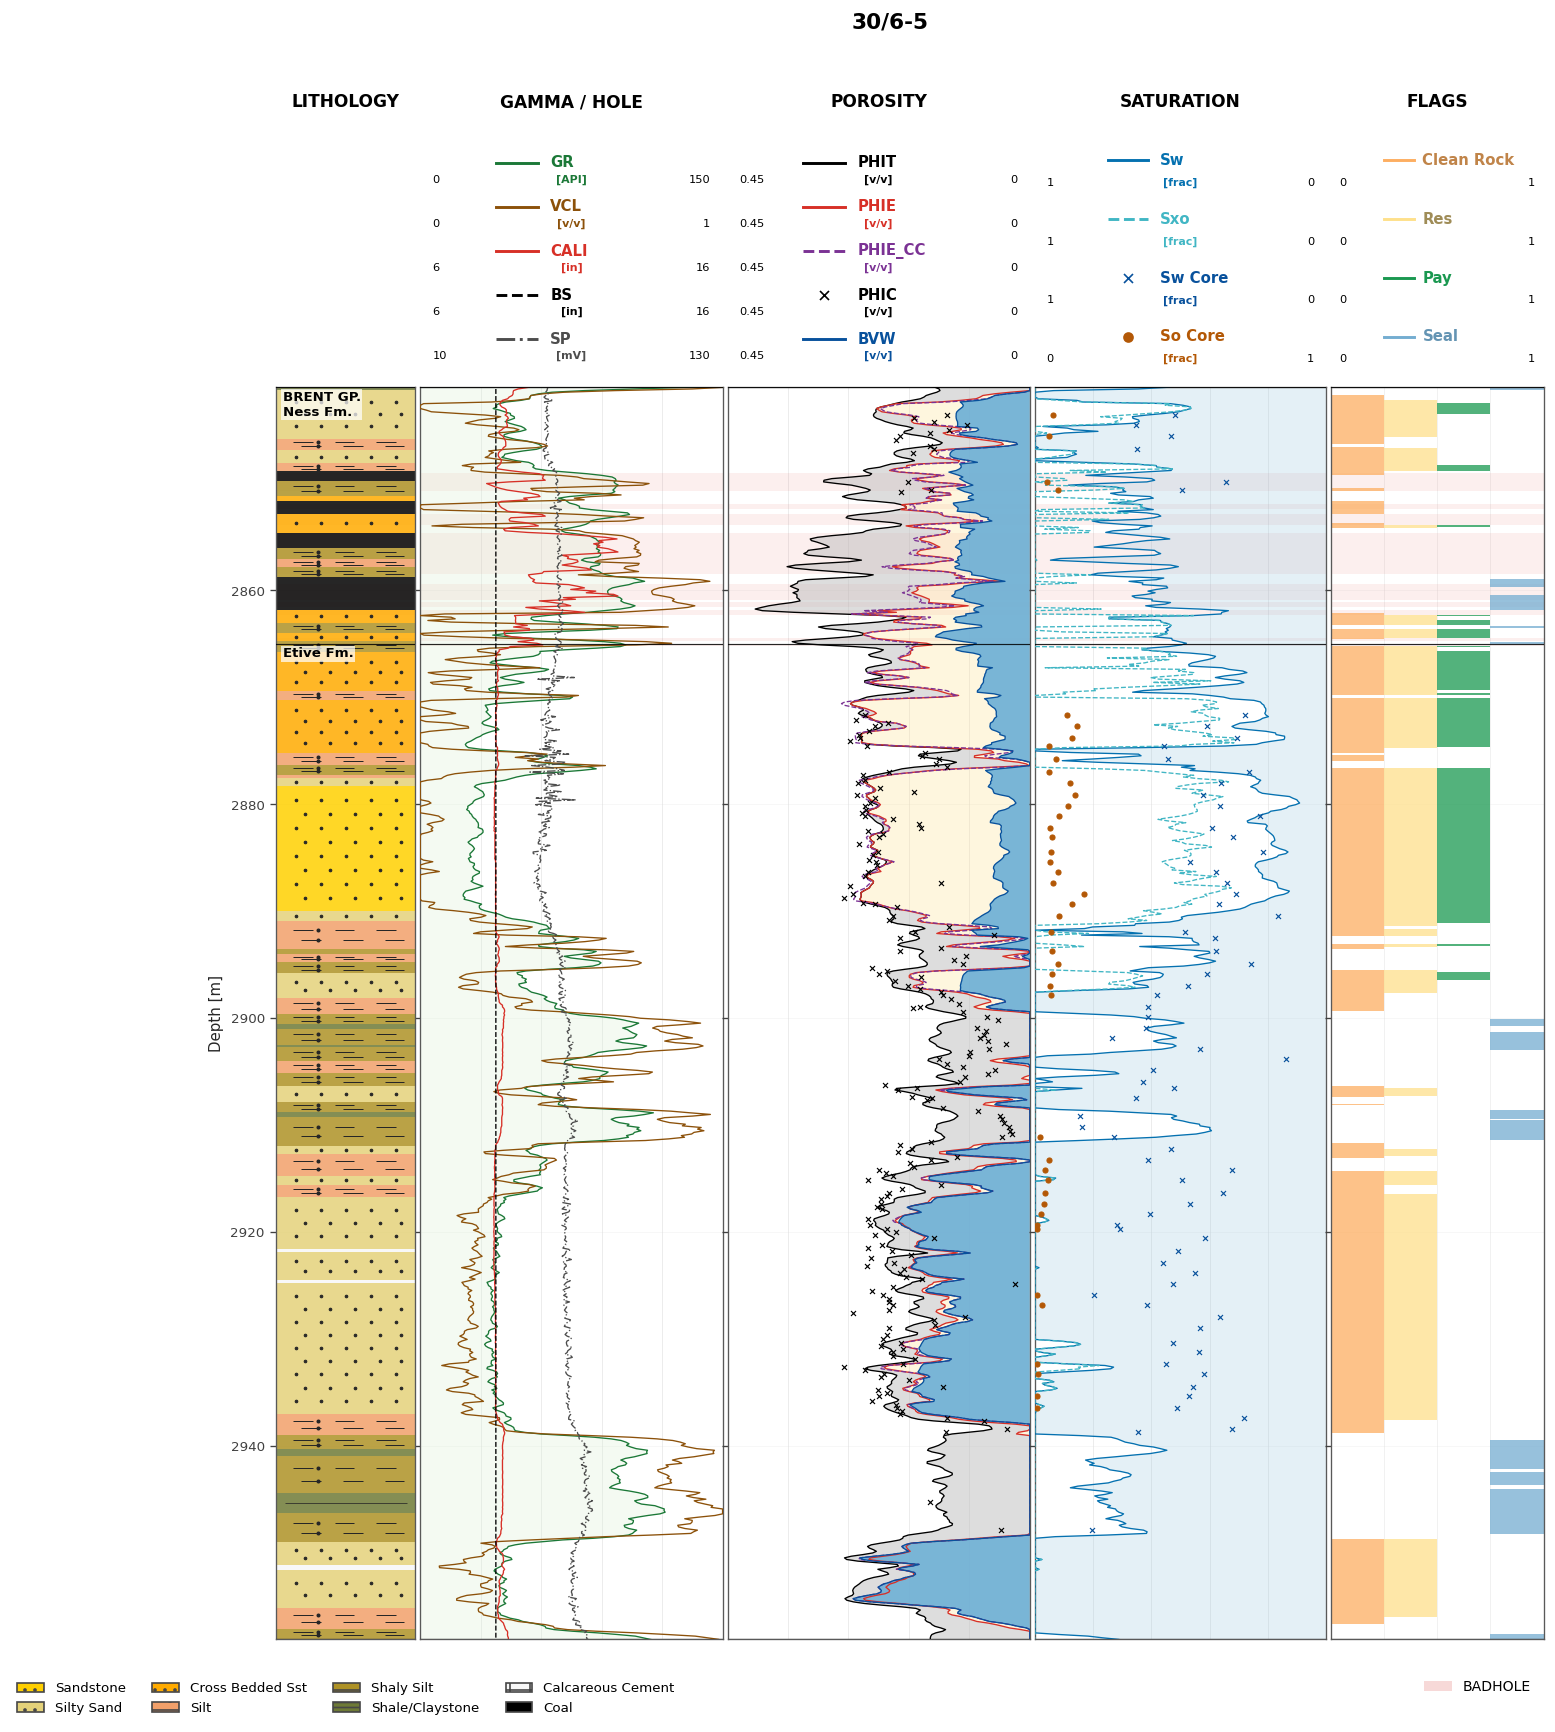

In [11]:
pp.plot(result, top=2841, bottom=2958,
        tracks=["LITHOLOGY", "GAMMA / HOLE", "POROSITY", "SATURATION", "FLAGS"])

The Ness Formation is thin, interbedded sand, silt and coal: about half of it is net
rock and only a few metres are pay. The Etive Formation is mostly net reservoir,
but only its upper part, above about 2900 m, is pay; below that the sand is wet.

## 5. Volumetrics: HCPV, OOIP

With net pay and pay-averaged porosity and $S_w$ in hand, we estimate hydrocarbon
in place. The summation functions use **field units** (acres, feet):

- `calculate_hcpv(area_acres, net_pay_ft, porosity, sw, bo, bg, ngi)` -> an
  `HCPVResult` (acre-ft, bbl, m3, OOIP, OGIP).
- `calculate_ooip(area_acres, net_pay_ft, porosity, sw, bo, recovery_factor)`
- `calculate_ogip(area_acres, net_pay_ft, porosity, sw, bg, recovery_factor)`

`formation_summary(rank="group")` gives the Brent Group as one row, with porosity
and $S_w$ already averaged **over the net-pay samples only** (averaging over non-pay
would dilute the numbers). We convert the net-pay thickness from metres to feet and
assume a nominal 1000-acre drainage area. The formation volume factors are left at
their defaults, `bo=1.2` and `bg=0.005`, and the result gives the oil and the gas figure
for the same pore volume: read the one for your fluid.

In [12]:
from petrophys.evaluation.summaries import calculate_hcpv, calculate_ooip

group = result.formation_summary(rank="group").set_index("Formation").loc["BRENT GP."]
pay = dict(area_acres=1000, net_pay_ft=group["Net Pay (m)"] * 3.281, porosity=group["Avg PHIE"], sw=group["Avg Sw"])
calculate_hcpv(**pay)

HCPVResult(area_acres=1000, net_pay_ft=np.float64(89.00353935499984), avg_porosity=0.21781661628401858, avg_sw=0.2831337456524076, hcpv_acft=np.float64(13897.49163860497), hcpv_bbl=np.float64(107822299.12895279), hcpv_m3=np.float64(17142376.218304556), ooip_bbl=np.float64(89851915.94079399), ooip_stb=np.float64(89851915.94079399), ogip_mcf=np.float64(121074947.15552649), ogip_bcf=np.float64(121.07494715552649))

In [13]:
calculate_ooip(**pay, recovery_factor=0.30)

{'ooip_stb': np.float64(89851915.940794),
 'ooip_mbbl': np.float64(89851.915940794),
 'ooip_mmbbl': np.float64(89.851915940794),
 'ooip_m3': np.float64(14285313.515253799),
 'recoverable_stb': np.float64(26955574.7822382),
 'recoverable_mbbl': np.float64(26955.5747822382),
 'recovery_factor': 0.3}

## 6. Tie it together: the reservoir summary

The group row of `formation_summary` is the one-line summary you would hand to a
geologist or reservoir engineer:

In [14]:
group[["Top", "Bottom", "Gross (m)", "Net Pay (m)", "Pay/Gross", "Avg PHIE", "Avg Sw", "Avg VCL",
       "Avg Perm (mD)", "BVW"]].to_frame("BRENT GP.").T.round(3)

,Top,Bottom,Gross (m),Net Pay (m),Pay/Gross,Avg PHIE,Avg Sw,Avg VCL,Avg Perm (mD),BVW
BRENT GP.,2841.0,2958.0,117.043,27.127,0.232,0.218,0.283,0.07,547.448,0.062


### Reading the summary

This one row is the distilled output of the entire Part A pipeline: an interbedded
sand-shale package of 117 m with 27 m of pay, whose pay is clean (clay volume about
0.07), porous (about 0.22) and low in $S_w$ (about 0.28, so high hydrocarbon
saturation). BVW is near irreducible above about 2900 m and rises through the
transition zone below, and the MHI shows the oil above 2900 m as moveable. Every
number traces back to a physical model you can defend: $V_{cl}$ from GR and
neutron-density, effective porosity corrected to the core plugs, $S_w$ from the
operator's Archie parameters (with Simandoux in the shaly beds), permeability from
the core-calibrated model of the permeability step (lesson 08), and volumetrics
from field-unit summation.

## 7. Validation against the operator's completion report

Net pay is cutoff arithmetic, so "is it right?" can only be answered against an
independent evaluation. For 30/6-5 one exists: Statoil's completion report holds a
computed log with a petrophysical evaluation (prepared by H.M. Strømmevold, 13 Dec
1981) and a zone-by-zone table for 2800-2980 m. Its header states the parameters:
$a = 0.80$, $m = n = 2$, $R_w$ = 0.070 ohm.m at 230 degF, a shale resistivity of
8.0 ohm.m, and cutoffs $V_{sh} < 0.40$, $\phi > 0.12$ and, for pay, $S_w < 0.65$.
Their result:

| zone | top - base (m) | net sand (m) | net pay (m) | pay porosity | pay $S_w$ |
|---|---|---|---|---|---|
| Ness | 2841 - 2865 | 5.50 | 4.25 | 0.177 | 0.535 |
| Etive | 2865 - 2895 | 25.75 | 20.75 | 0.228 | 0.198 |
| Drake sand | 2895 - 2939 | 22.75 | 1.75 | 0.200 | 0.551 |

A shale resistivity belongs to a shaly-sand equation. The report does not name it;
with their 8.0 ohm.m (`rtsh=8.0`), the Indonesia equation reproduces the Ness and
Drake saturations closely.

The operator's 1981 zonation differs from the bundled tops: it ends the Etive at
2895 m and calls 2895-2939 m the Drake sand, whereas the bundled tops run the
Etive Fm down to 2958 m and start the Drake Fm below it. We use the operator's
zone boundaries so that the comparison is like for like. Their "net sand" passes the
clay and porosity cutoffs: our net reservoir.

Replicating their evaluation is a matter of settings: their constants with
`sw_model="indonesia"` and `rtsh=8.0`, their cutoffs, and their zones (`zones=`, each
with a `name`, `top` and `bottom`), which `zone_summary` then reports.

In [15]:
zones = [{"name": "Ness", "top": 2841, "bottom": 2865},
         {"name": "Etive", "top": 2865, "bottom": 2895},
         {"name": "Drake sand", "top": 2895, "bottom": 2939}]
statoil = dict(operator, sw_model="indonesia", rtsh=8.0, vcl_cutoff=0.40, phie_cutoff=0.12, sw_cutoff=0.65, zones=zones)
columns = ["Zone", "Net Reservoir (m)", "Net Pay (m)", "Avg PHIE", "Avg Sw"]
pp.interpret(well, **statoil).zone_summary()[columns].round(3)

,Zone,Net Reservoir (m),Net Pay (m),Avg PHIE,Avg Sw
0,Ness,5.791,4.419,0.195,0.533
1,Etive,23.622,23.622,0.220,0.242
2,Drake sand,20.269,1.829,0.164,0.557


The main pay call is reproduced. Net sand agrees within about 2.5 m in every zone.
In the shaly Ness and the Drake sand, pay and pay $S_w$ match closely: 4.4 m against
4.25 m at $S_w$ 0.533 against 0.535, and 1.8 m against 1.75 m at 0.557 against 0.551.
The clean Etive differs most: about 23.6 m of pay against their 20.75 m, at a similar
pay porosity (0.220 against 0.228) and a higher pay $S_w$ (0.24 against 0.20). In
clean sand the shale term hardly changes $S_w$, so that difference comes from the
porosity and resistivity read from the logs, not from the equation.

The more important lesson is $R_w$. With an under-estimated $R_w = 0.03$ ohm.m (a
common textbook guess for North Sea sands), the Drake sand - low deep resistivity at
good porosity, a classic wet response - starts to book pay:

In [16]:
pp.interpret(well, **dict(statoil, rw=0.03)).zone_summary()[columns].round(3)

,Zone,Net Reservoir (m),Net Pay (m),Avg PHIE,Avg Sw
0,Ness,5.791,5.791,0.181,0.381
1,Etive,23.622,23.622,0.220,0.161
2,Drake sand,20.269,10.668,0.171,0.555


The Drake pay jumps from about 2 m to about 11 m, half of its net reservoir and all
of it false pay in water-bearing sand, and every metre of Ness and Etive net sand turns
to pay. The operator's higher $R_w$ kills the false pay - and that $R_w$ is not a
guess: lesson 06 found the same water from a salinity estimate and a local SP pick,
and lesson 07's Pickett plot put the operator's water line on the lower edge of the
water-bearing Statfjord sandstone. $R_w$ is the single most consequential parameter
in the chain, and a second, independent $R_w$ route is what tells you whether a
wet-looking sand is really wet before any pay is booked.

## Pitfalls & parameter choices

- **Average over pay, not over gross.** Diluting porosity/$S_w$ with non-pay
  samples silently deflates OOIP; `formation_summary` averages over net pay.
- **Cutoffs are decisions, not constants.** The standard cutoffs (`STANDARD_CUTOFFS`)
  are a starting point; net pay is sensitive to them, so document and justify the
  values you use (`vcl_cutoff`, `phie_cutoff`, `sw_cutoff`).
- **RQI/FZI inherit permeability uncertainty.** Because $RQI \propto \sqrt{k}$, a
  factor-of-2 error in $k$ is only a 40% error in RQI - FZI is more robust than raw
  $k$, which is why flow units are a stable way to zone a reservoir.
- **BVW constancy is diagnostic, not guaranteed.** Rising BVW down-section is a real
  transition zone; don't force a single water contact through it.
- **Field units in volumetrics.** `calculate_hcpv` and friends expect acres and
  feet - convert metric thicknesses first (x3.281).

## Recap

- **RQI / $\phi_z$ / FZI** turn porosity and permeability into a hydraulic quality
  metric; clustering FZI gives **flow units** that zone the reservoir.
- **BVW** ($\phi_e S_w$) near-constant = rock at irreducible water; **MHI**
  ($S_w/S_{xo}$) $< 0.7$ = moveable hydrocarbon.
- **Net pay** is a three-stage filter: net rock (clay) -> net reservoir (porosity)
  -> net pay (saturation); `formation_summary` and `zone_summary` report it.
- **Volumetrics** (`calculate_hcpv`, `calculate_ooip`) convert pay thickness,
  porosity and $S_w$ into hydrocarbon in place - in field units.
- An operator's evaluation is reproduced with settings (`a`, `m`, `n`, `rw`, the
  cutoffs, `zones`), and the comparison shows which parameter matters most: $R_w$.

## Try it yourself

> **Exercise 1.** Tighten the porosity cutoff from the standard 0.08 to the
> operator's 0.12 (`phie_cutoff=0.12`), and $S_w$ from 0.60 to 0.50
> (`sw_cutoff=0.5`). How do net-pay thickness and OOIP respond? Which cutoff is the
> net pay more sensitive to here?
>
> **Exercise 2.** Re-run `calculate_flow_units` with `n_units=4`. Do the extra
> units carve out genuinely different rock (look at the FZI plot), or just split an
> existing cluster?
>
> **Exercise 3.** Compute OOIP for drainage areas from 500 to 2000 acres. Since OOIP
> is linear in area, what does that tell you about which input dominates a
> volumetric estimate's uncertainty?
>
> **Exercise 4.** Repeat the operator comparison with `skip_steps=["bad_hole"]`.
> How much of the Ness pay difference does the bad-hole flag explain?

## What's next

This closes Part A - Foundations. You have an end-to-end deterministic
petrophysical workflow: from raw logs to clay volume, porosity, saturation,
permeability, and finally reservoir quality, net pay and volumetrics.

Part B opens with **10 - The Dynamic Workflow Engine: a Glass Box**, where
we look inside `pp.interpret`: its step trace - which methods it chose, which steps
it skipped and why - and how to steer it with settings. Later Part B lessons cover
formation-by-formation analysis, core calibration, NMR and saturation-height
modelling.